# Datheon Internship - Task 01

# Iris Multi-Class Classification

In [11]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.tree import DecisionTreeClassifier
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score, classification_report, confusion_matrix
print("All libraries imported successfully!")

All libraries imported successfully!


# Step 02 - Load Iris Dataset

In [2]:
df = pd.read_csv("Iris.csv")

print("Dataset loaded successfully!")

print("\nDataset Shape:")
print(df.shape)

print("\nFirst 5 Rows:")
display(df.head())

print("\nColumn Names:")
print(df.columns.tolist())

print("\nMissing Values:")
print(df.isnull().sum())

print("\nSpecies Distribution:")
print(df["species"].value_counts())

Dataset loaded successfully!

Dataset Shape:
(150, 5)

First 5 Rows:


,sepal_length,sepal_width,petal_length,petal_width,species
0,5.1,3.5,1.4,0.2,setosa
1,4.9,3.0,1.4,0.2,setosa
2,4.7,3.2,1.3,0.2,setosa
3,4.6,3.1,1.5,0.2,setosa
4,5.0,3.6,1.4,0.2,setosa



Column Names:
['sepal_length', 'sepal_width', 'petal_length', 'petal_width', 'species']

Missing Values:
sepal_length    0
sepal_width     0
petal_length    0
petal_width     0
species         0
dtype: int64

Species Distribution:
species
setosa        50
versicolor    50
virginica     50
Name: count, dtype: int64


# Step 03 - Exploratory Data Analysis

In [7]:
print("Statistical Summary:")
display(df.describe())

# Set visualization style
sns.set_theme(style="whitegrid")


Statistical Summary:


,sepal_length,sepal_width,petal_length,petal_width
count,150.000000,150.000000,150.000000,150.000000
mean,5.843333,3.057333,3.758000,1.199333
std,0.828066,0.435866,1.765298,0.762238
min,4.300000,2.000000,1.000000,0.100000
25%,5.100000,2.800000,1.600000,0.300000
50%,5.800000,3.000000,4.350000,1.300000
75%,6.400000,3.300000,5.100000,1.800000
max,7.900000,4.400000,6.900000,2.500000


### 1. Species Distribution

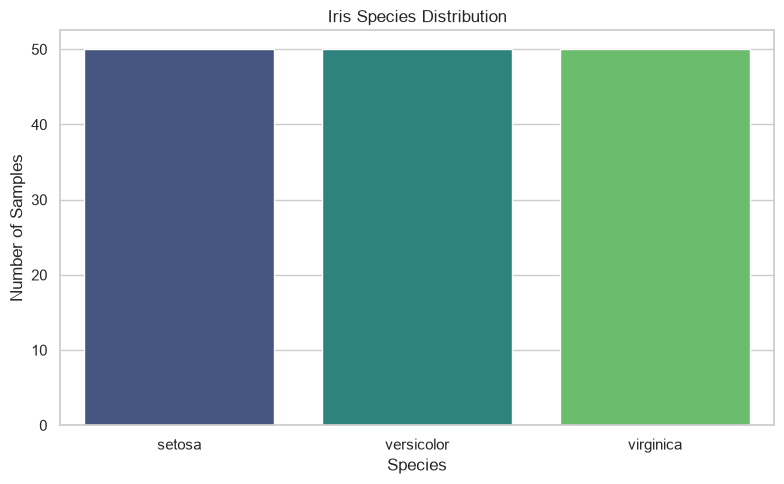

In [5]:
plt.figure(figsize=(8, 5))
sns.countplot(data=df, x="species", hue="species",
              palette="viridis", legend=False)
plt.title("Iris Species Distribution")
plt.xlabel("Species")
plt.ylabel("Number of Samples")
plt.tight_layout()
plt.show()

### 2. Pairplot

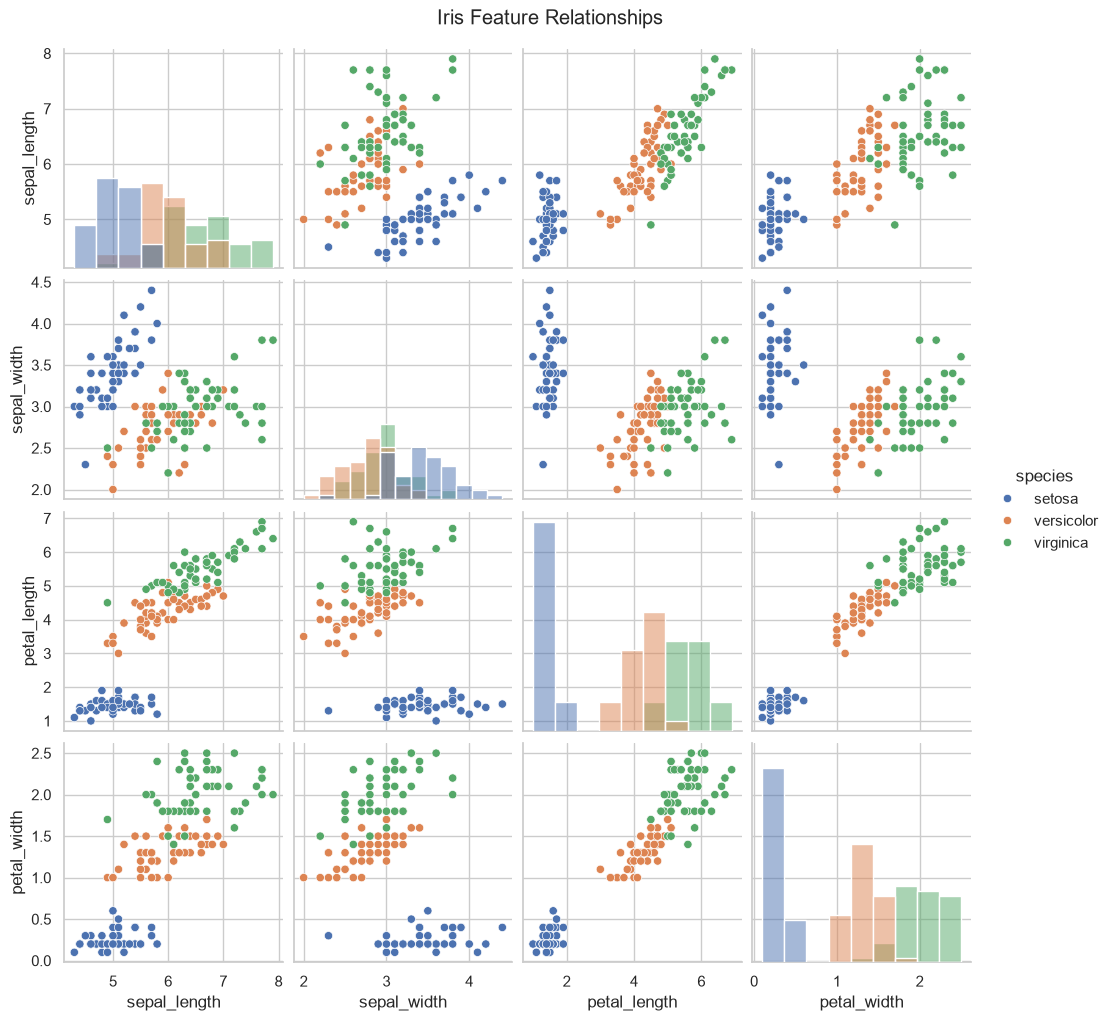

In [6]:
# 2. Pairplot
sns.pairplot(df, hue="species", diag_kind="hist")
plt.suptitle("Iris Feature Relationships", y=1.02)
plt.show()

# 3. Correlation Heatmap

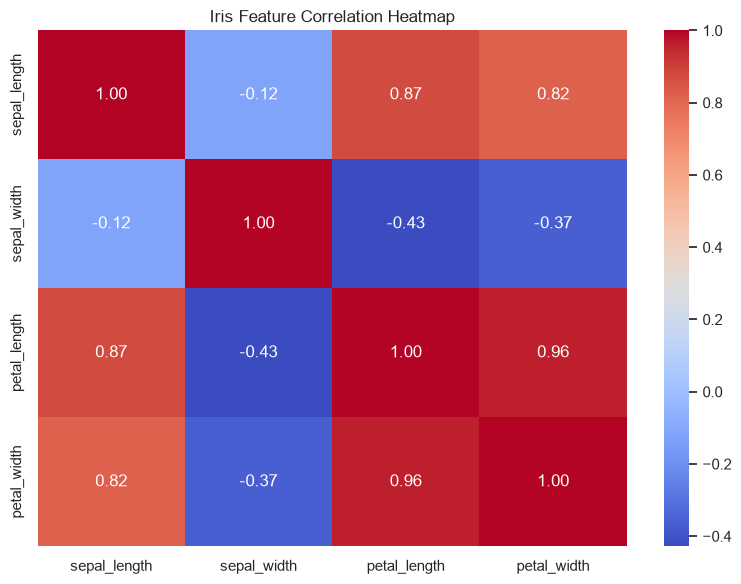

EDA completed successfully!


In [4]:
plt.figure(figsize=(8, 6))

correlation = df.drop(columns=["species"]).corr()

sns.heatmap(
    correlation,
    annot=True,
    cmap="coolwarm",
    fmt=".2f"
)

plt.title("Iris Feature Correlation Heatmap")
plt.tight_layout()
plt.show()

print("EDA completed successfully!")

# Step 04 - Train/Test Split

In [8]:
# Step 04 - Train/Test Split

# Separate features and target
X = df.drop(columns=["species"])
y = df["species"]

# Split dataset: 80% training, 20% testing
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.20,
    random_state=42,
    stratify=y
)

print("Training samples:", X_train.shape[0])
print("Testing samples:", X_test.shape[0])

print("\nTraining class distribution:")
print(y_train.value_counts())

print("\nTesting class distribution:")
print(y_test.value_counts())

Training samples: 120
Testing samples: 30

Training class distribution:
species
setosa        40
virginica     40
versicolor    40
Name: count, dtype: int64

Testing class distribution:
species
setosa        10
virginica     10
versicolor    10
Name: count, dtype: int64


# Step 05 - Feature Scaling

In [9]:
scaler = StandardScaler()

# Fit only on training data
X_train_scaled = scaler.fit_transform(X_train)

# Transform testing data using the same scaler
X_test_scaled = scaler.transform(X_test)

print("Feature scaling completed successfully!")

print("\nScaled Training Data Shape:")
print(X_train_scaled.shape)

print("\nScaled Testing Data Shape:")
print(X_test_scaled.shape)

Feature scaling completed successfully!

Scaled Training Data Shape:
(120, 4)

Scaled Testing Data Shape:
(30, 4)


# Step 06 - Model Training

## Logistic Regression

In [12]:
logistic_model = LogisticRegression(
    max_iter=1000,
    random_state=42
)

logistic_model.fit(X_train_scaled, y_train)

,"random_state random_state: int, RandomState instance, default=NoneOnly used for `solver` == 'sag', 'saga' or 'liblinear' to shuffle thedata. It has no effect on the other solvers.See :term:`Glossary <random_state>` for details.",42
,"max_iter max_iter: int, default=100Maximum number of iterations taken for the solvers to converge.",1000
,"penalty penalty: {'l1', 'l2', 'elasticnet', None}, default='l2'Specify the norm of the penalty:- `None`: no penalty is added;- `'l2'`: add an L2 penalty term and it is the default choice;- `'l1'`: add an L1 penalty term;- `'elasticnet'`: both L1 and L2 penalty terms are added... warning:: Some penalties may not work with some solvers. See the parameter `solver` below, to know the compatibility between the penalty and solver... versionadded:: 0.19 l1 penalty with SAGA solver (allowing 'multinomial' + L1).. deprecated:: 1.8 `penalty` was deprecated in version 1.8 and will be removed in 1.10. Use `l1_ratio` and `C` instead. `l1_ratio=0` for `penalty='l2'`, `l1_ratio=1` for `penalty='l1'`, `l1_ratio` set to any float between 0 and 1 for `penalty='elasticnet'`, and `C=np.inf` for `penalty=None`.",'deprecated'
,"C C: float, default=1.0Inverse of regularization strength; must be a positive float.Like in support vector machines, smaller values specify strongerregularization. `C=np.inf` results in unpenalized logistic regression.For a visual example on the effect of tuning the `C` parameterwith an L1 penalty, see::ref:`sphx_glr_auto_examples_linear_model_plot_logistic_path.py`.",1.0
,"l1_ratio l1_ratio: float, default=0.0The Elastic-Net mixing parameter, with `0 <= l1_ratio <= 1`. Setting`l1_ratio=1` gives a pure L1-penalty, setting `l1_ratio=0` a pure L2-penalty.Any value between 0 and 1 gives an Elastic-Net penalty of the form`l1_ratio * L1 + (1 - l1_ratio) * L2`... warning:: Certain values of `l1_ratio`, i.e. some penalties, may not work with some solvers. See the parameter `solver` below, to know the compatibility between the penalty and solver... versionchanged:: 1.8 Default value changed from None to 0.0... deprecated:: 1.8 `None` is deprecated and will be removed in version 1.10. Always use `l1_ratio` to specify the penalty type.",0.0
,"dual dual: bool, default=FalseDual (constrained) or primal (regularized, see also:ref:`this equation <regularized-logistic-loss>`) formulation. Dual formulationis only implemented for l2 penalty with liblinear solver. Prefer `dual=False`when n_samples > n_features.",False
,"tol tol: float, default=1e-4Tolerance for stopping criteria.",0.0001
,"fit_intercept fit_intercept: bool, default=TrueSpecifies if a constant (a.k.a. bias or intercept) should beadded to the decision function.",True
,"intercept_scaling intercept_scaling: float, default=1Useful only when the solver `liblinear` is usedand `self.fit_intercept` is set to `True`. In this case, `x` becomes`[x, self.intercept_scaling]`,i.e. a ""synthetic"" feature with constant value equal to`intercept_scaling` is appended to the instance vector.The intercept becomes``intercept_scaling * synthetic_feature_weight``... note:: The synthetic feature weight is subject to L1 or L2 regularization as all other features. To lessen the effect of regularization on synthetic feature weight (and therefore on the intercept) `intercept_scaling` has to be increased.",1
,"class_weight class_weight: dict or 'balanced', default=NoneWeights associated with classes in the form ``{class_label: weight}``.If not given, all classes are supposed to have weight one.The ""balanced"" mode uses the values of y to automatically adjustweights inversely proportional to class frequencies in the input dataas ``n_samples / (n_classes * np.bincount(y))``.Note that these weights will be multiplied with sample_weight (passedthrough the fit method) if sample_weight is specified... versionadded:: 0.17 *class_weight='balanced'*",None
,"solver solver: {'lbfgs', 'liblinear', 'newton-cg', 'newton-cholesky', 'sag', 'saga'}, default='lbfgs'Algorithm to use in 

## Decision Tree

In [13]:
tree_model = DecisionTreeClassifier(
    random_state=42
)

tree_model.fit(X_train_scaled, y_train)

print("Logistic Regression trained successfully!")
print("Decision Tree trained successfully!")

Logistic Regression trained successfully!
Decision Tree trained successfully!


## Predictions

In [14]:
y_pred_logistic = logistic_model.predict(X_test_scaled)
y_pred_tree = tree_model.predict(X_test_scaled)

print("\nPredictions generated successfully!")


Predictions generated successfully!


# Step 07 - Model Evaluation & Comparison

In [15]:
models = {
    "Logistic Regression": y_pred_logistic,
    "Decision Tree": y_pred_tree
}

results = []

for model_name, predictions in models.items():

    accuracy = accuracy_score(y_test, predictions)
    precision = precision_score(
        y_test, predictions, average="weighted", zero_division=0
    )
    recall = recall_score(
        y_test, predictions, average="weighted", zero_division=0
    )
    f1 = f1_score(
        y_test, predictions, average="weighted", zero_division=0
    )

    results.append({
        "Model": model_name,
        "Accuracy": accuracy,
        "Precision": precision,
        "Recall": recall,
        "F1 Score": f1
    })

    print(f"\n{'=' * 50}")
    print(f"Model: {model_name}")
    print(f"{'=' * 50}")

    print(classification_report(
        y_test, predictions, zero_division=0
    ))

results_df = pd.DataFrame(results)

print("\nMODEL COMPARISON")
display(results_df.round(4))


Model: Logistic Regression
              precision    recall  f1-score   support

      setosa       1.00      1.00      1.00        10
  versicolor       0.90      0.90      0.90        10
   virginica       0.90      0.90      0.90        10

    accuracy                           0.93        30
   macro avg       0.93      0.93      0.93        30
weighted avg       0.93      0.93      0.93        30


Model: Decision Tree
              precision    recall  f1-score   support

      setosa       1.00      1.00      1.00        10
  versicolor       0.90      0.90      0.90        10
   virginica       0.90      0.90      0.90        10

    accuracy                           0.93        30
   macro avg       0.93      0.93      0.93        30
weighted avg       0.93      0.93      0.93        30


MODEL COMPARISON


,Model,Accuracy,Precision,Recall,F1 Score
0,Logistic Regression,0.9333,0.9333,0.9333,0.9333
1,Decision Tree,0.9333,0.9333,0.9333,0.9333


# Step 08 - Confusion Matrix Visualization

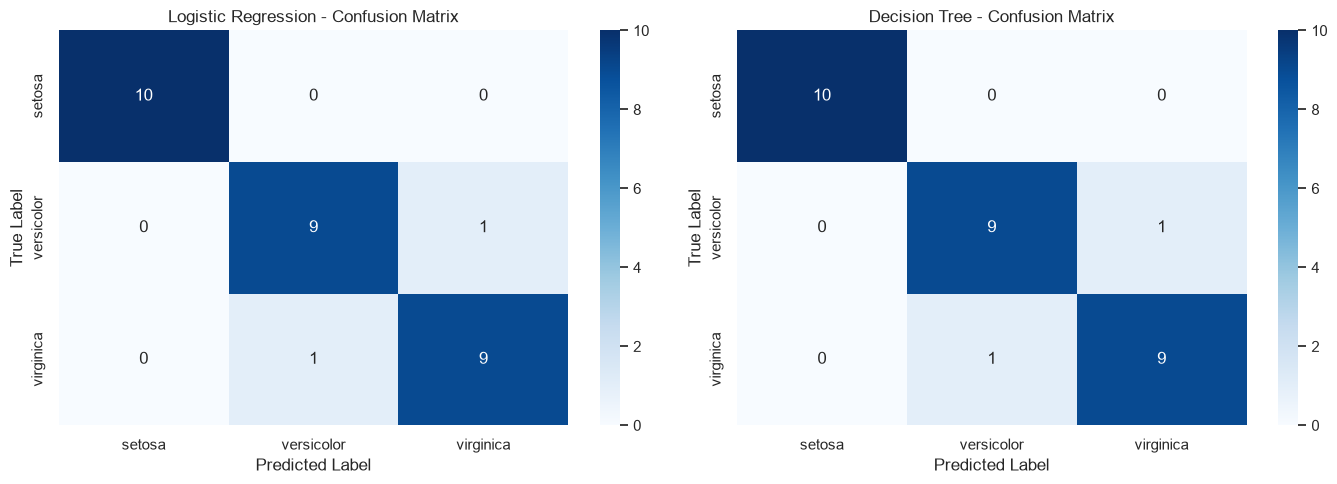

Confusion matrices generated successfully!


In [16]:
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

model_predictions = [
    ("Logistic Regression", y_pred_logistic),
    ("Decision Tree", y_pred_tree)
]

class_names = logistic_model.classes_

for ax, (name, predictions) in zip(
    axes, model_predictions
):
    cm = confusion_matrix(
        y_test,
        predictions,
        labels=class_names
    )

    sns.heatmap(
        cm,
        annot=True,
        fmt="d",
        cmap="Blues",
        xticklabels=class_names,
        yticklabels=class_names,
        ax=ax
    )

    ax.set_title(f"{name} - Confusion Matrix")
    ax.set_xlabel("Predicted Label")
    ax.set_ylabel("True Label")

plt.tight_layout()
plt.show()

print("Confusion matrices generated successfully!")

# Step 09 - Decision Boundary Visualization

c:\Users\sudee\OneDrive\Desktop\Datheon-ML-DataScience-Internship\.venv\Lib\site-packages\sklearn\inspection\_plot\decision_boundary.py:392: UserWarning: 'cmap' is ignored in favor of 'multiclass_colors' in the multiclass case.
  warnings.warn(
c:\Users\sudee\OneDrive\Desktop\Datheon-ML-DataScience-Internship\.venv\Lib\site-packages\sklearn\inspection\_plot\decision_boundary.py:392: UserWarning: 'cmap' is ignored in favor of 'multiclass_colors' in the multiclass case.
  warnings.warn(


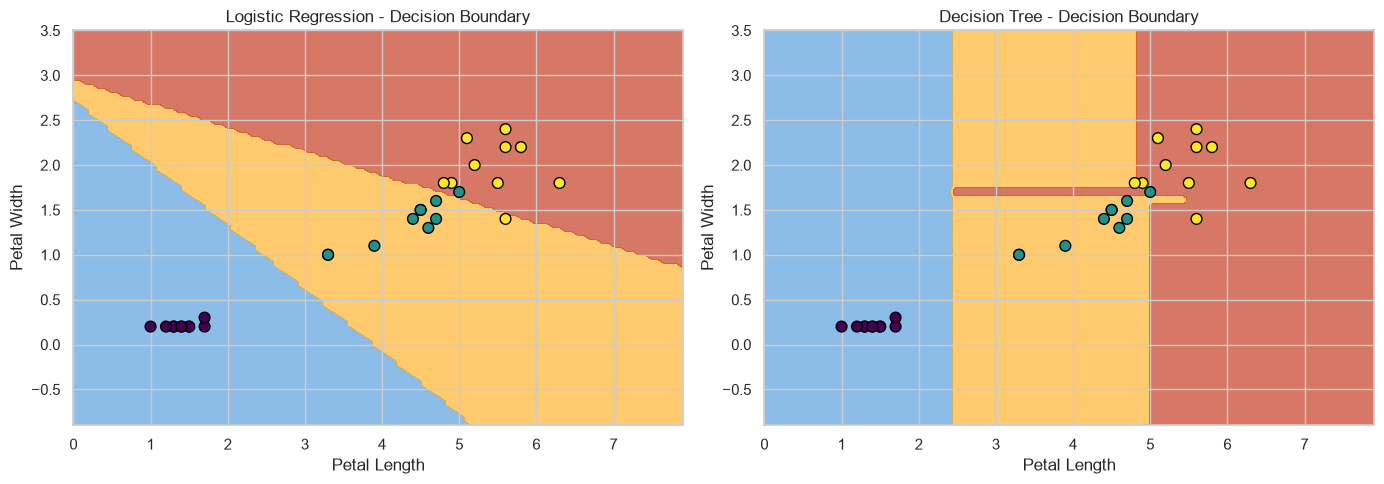

Decision boundary visualization completed!


In [17]:
from sklearn.inspection import DecisionBoundaryDisplay
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import LabelEncoder

# Use two features for 2D visualization
features = ["petal_length", "petal_width"]

X_2d = df[features]
y_2d = LabelEncoder().fit_transform(df["species"])

X_train_2d, X_test_2d, y_train_2d, y_test_2d = train_test_split(
    X_2d,
    y_2d,
    test_size=0.2,
    random_state=42,
    stratify=y_2d
)

models_2d = {
    "Logistic Regression": make_pipeline(
        StandardScaler(),
        LogisticRegression(max_iter=1000, random_state=42)
    ),
    "Decision Tree": DecisionTreeClassifier(
        random_state=42
    )
}

fig, axes = plt.subplots(1, 2, figsize=(14, 5))

for ax, (name, model) in zip(axes, models_2d.items()):

    model.fit(X_train_2d, y_train_2d)

    DecisionBoundaryDisplay.from_estimator(
        model,
        X_2d,
        response_method="predict",
        cmap="Pastel1",
        alpha=0.6,
        ax=ax
    )

    scatter = ax.scatter(
        X_test_2d.iloc[:, 0],
        X_test_2d.iloc[:, 1],
        c=y_test_2d,
        cmap="viridis",
        edgecolor="black",
        s=60
    )

    ax.set_title(f"{name} - Decision Boundary")
    ax.set_xlabel("Petal Length")
    ax.set_ylabel("Petal Width")

plt.tight_layout()
plt.show()

print("Decision boundary visualization completed!")


## Final Results and Conclusion

### Project: Iris Multi-Class Classification

This project implemented and evaluated two supervised machine learning models using the Iris dataset.

**Models:**
- Logistic Regression
- Decision Tree Classifier

**Dataset:** 150 samples, 3 species, 4 numerical features.

**Train/Test Split:** 80% / 20%, stratified.

### Model Performance

| Model | Accuracy | Precision | Recall | F1 |
|---|---|---|---|---|
| Logistic Regression | 93.33% | 93.33% | 93.33% | 93.33% |
| Decision Tree | 93.33% | 93.33% | 93.33% | 93.33% |

### Key Findings

1. Both models correctly classified 28 of 30 test samples.
2. Setosa achieved 100% precision and recall.
3. Most classification errors occurred between Versicolor and Virginica.
4. Petal length and petal width are useful features for distinguishing Iris species.
5. Logistic Regression produced linear decision boundaries, while Decision Tree produced axis-aligned boundaries.

### Conclusion

Both models achieved identical test accuracy of 93.33%. The results demonstrate successful implementation of an end-to-end multi-class classification workflow.

The evaluation is based on a small test set of 30 samples, so additional cross-validation would help assess model stability.